# 04 — Microstructure and L2 Instability

**Purpose:** characterize the order-book features from which the framework's within-regime **noise state** $Q_t$ would be identified (framework v2.1, §5.3 and §11), and start the empirical study of the OBI dead-band $\varepsilon$.

The noise chain is only useful if its inputs measure *how cleanly a regime is expressed*, not something the model already sees. Three properties are therefore tested, not assumed:

| Property | Why it matters | Section |
|---|---|---|
| Not a proxy for activity or volatility | Event-sampled path statistics grow mechanically with the number of book updates; $Q_t$ must not just relearn volume or $\sigma$ | 8 |
| Not a proxy for the clock | Framework rule: $Q_t$ must not learn "overnight versus US session" | 9 |
| Dispersion, not direction | $Q_t$ may scale $\sigma$ only; it must not predict the sign of the next return | 13 |

**Data window.** Clean instability statistics exist only from **1 Oct 2026, 10:55 UTC** (collector L2 correction, after the Deribit migration). This is a few days of history: enough to explore and to reject bad candidates, **not** to calibrate thresholds or $\varepsilon$ (the handoff asks for at least 30 days, better 60–90).

It does **not**: impute, winsorize, standardize with full-sample statistics, choose $\varepsilon$, or fit the noise chain. All timestamps are UTC.

## 1. Environment and read-only connection

In [1]:
from pathlib import Path
import os
import math
import time
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.max_columns", 220)
pd.set_option("display.max_rows", 220)
pd.set_option("display.width", 200)

load_dotenv()
data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"
if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")
print(f"Research DB:        {DB_PATH}")
print("Session time zone:", con.execute("SELECT current_setting('TimeZone')").fetchone()[0])


def relation_columns(name):
    return set(con.execute(f"DESCRIBE SELECT * FROM {name}").df()["column_name"])

Research DB:        D:\MarketData\Deribit\database\research.duckdb
Session time zone: UTC


## 2. Load the L2 block

Two sources:

- `time_series_feature_state`: model-facing L2 features, returns (index), volatility, activity and the readiness flag `l2_instability_features_ready`;
- `canonical_market_state`: raw collector audit fields (`book_out_of_order_update_count`, `book_event_time_monotonic`, `book_obi_20_duration_ms`) and the collector v0.3 fields (`book_max_update_gap_ms`, intrawindow mid-path statistics), which exist only from the v0.3 deployment.

Only states with `l2_instability_features_ready` are analysed.

In [2]:
L2_FEATURES = [
    "book_twa_abs_obi_20",
    "book_obi_20_std",
    "book_obi_20_range",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_coherence_noise",
    "book_obi_20_raw_zero_cross_rate",
    "book_obi_20_reversal_strength_mean",
    "book_obi_20_reversal_strength_max",
]
L2_COUNTS = ["book_update_count", "book_obi_20_transition_count", "book_obi_20_raw_zero_cross_count"]
CONTEXT = [
    "return_5m", "realized_vol_1h_annualized", "log1p_volume_usd", "trade_count",
    "book_twa_spread_bps", "futures_spread_bps", "book_twa_obi_20",
    "book_twa_bid_depth_20", "book_twa_ask_depth_20", "minutes_to_expiry", "session_id",
]

ts_cols = relation_columns("time_series_feature_state")
wanted = ["state_id", "state_time", "underlying", "l2_instability_features_ready"] + L2_FEATURES + L2_COUNTS + CONTEXT
missing = [c for c in wanted if c not in ts_cols]
sel = [c for c in wanted if c in ts_cols]
if missing:
    print("Not in time_series_feature_state:", missing)

feat = con.execute(f"SELECT {', '.join(sel)} FROM time_series_feature_state ORDER BY underlying, state_time").df()
feat["state_time"] = pd.to_datetime(feat["state_time"], utc=True)

cms_cols = relation_columns("canonical_market_state")
AUDIT = [c for c in [
    "book_out_of_order_update_count", "book_event_time_monotonic", "book_obi_20_duration_ms",
    "book_stats_coverage_ms", "book_max_update_gap_ms",
    "mid_path_valid_points", "mid_path_increment_count", "mid_path_realized_variance",
    "mid_path_return_sign_flips", "mid_path_zero_increments", "mid_path_nonzero_increments",
    "mid_path_max_abs_log_return", "collector_version",
] if c in cms_cols]
audit = con.execute(f"SELECT state_id, {', '.join(AUDIT)} FROM canonical_market_state").df()
l2 = feat.merge(audit, on="state_id", how="left")

ready = l2["l2_instability_features_ready"].fillna(False).astype(bool)
l2 = l2[ready].copy()
L2_FEATURES = [c for c in L2_FEATURES if c in l2.columns]
ASSETS = sorted(l2["underlying"].unique())

l2["utc_hour"] = l2["state_time"].dt.hour
l2["utc_date"] = l2["state_time"].dt.date
l2["weekend"] = l2["state_time"].dt.dayofweek >= 5
l2["log_updates"] = np.log1p(pd.to_numeric(l2["book_update_count"], errors="coerce"))
l2["abs_return_bps"] = 1e4 * pd.to_numeric(l2["return_5m"], errors="coerce").abs()

print(f"L2-ready states: {len(l2):,} | assets: {ASSETS}")
print(f"Window: {l2['state_time'].min()} → {l2['state_time'].max()}")
print(f"Audit/v0.3 fields found: {AUDIT}")
display(l2.groupby("underlying").agg(states=("state_id", "size"), first=("state_time", "min"), last=("state_time", "max"),
                                     days=("utc_date", "nunique")))

L2-ready states: 9,632 | assets: ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
Window: 2026-10-01 10:55:00+00:00 → 2026-10-06 07:55:00+00:00
Audit/v0.3 fields found: ['book_out_of_order_update_count', 'book_event_time_monotonic', 'book_obi_20_duration_ms', 'book_stats_coverage_ms', 'book_max_update_gap_ms', 'mid_path_valid_points', 'mid_path_increment_count', 'mid_path_realized_variance', 'mid_path_return_sign_flips', 'mid_path_zero_increments', 'mid_path_nonzero_increments', 'mid_path_max_abs_log_return', 'collector_version']


,states,first,last,days
underlying,,,,
AVAX,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6
BTC,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6
ETH,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6
HYPE,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6
SOL,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6
TRX,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6
XRP,1376,2026-10-01 10:55:00+00:00,2026-10-06 07:55:00+00:00,6


In [3]:
TAIL_QS = [0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999]


def clean_numeric(df, column):
    return pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()


def feature_summary(df, columns, group_col=None):
    rows = []
    it = [("ALL", df)] if group_col is None else df.groupby(group_col, observed=True)
    for g, d in it:
        for c in columns:
            s = clean_numeric(d, c)
            if s.empty:
                continue
            qv = s.quantile(TAIL_QS)
            rows.append({"group": g, "feature": c, "n": len(s),
                         "missing_pct": 100 * (len(d) - len(s)) / max(len(d), 1),
                         "zero_pct": 100 * (s == 0).mean(),
                         "mean": s.mean(), "std": s.std(), "skew": s.skew(), "excess_kurtosis": s.kurt(),
                         "min": s.min(), "q01": qv[0.01], "q05": qv[0.05], "median": qv[0.5],
                         "q95": qv[0.95], "q99": qv[0.99], "max": s.max()})
    return pd.DataFrame(rows)


def eta_squared(df, column, group_col):
    d = df[[column, group_col]].copy()
    d[column] = pd.to_numeric(d[column], errors="coerce")
    d = d.dropna()
    if len(d) < 50 or d[column].nunique() <= 10:
        return np.nan
    gm = d.groupby(group_col, observed=True)[column].transform("mean")
    return float(((gm - d[column].mean()) ** 2).sum() / ((d[column] - d[column].mean()) ** 2).sum())


def grid_acf(df, column, max_lag=24):
    """ACF on the exact 5-minute grid per asset (no gap bridging)."""
    rows = []
    for asset, g in df.groupby("underlying"):
        g = g.sort_values("state_time")
        x = pd.to_numeric(g[column], errors="coerce")
        for lag in range(1, max_lag + 1):
            lx = x.shift(lag)
            ok = x.notna() & lx.notna() & ((g["state_time"] - g["state_time"].shift(lag)) == pd.Timedelta(minutes=5 * lag))
            rows.append({"underlying": asset, "feature": column, "lag_minutes": 5 * lag, "n_pairs": int(ok.sum()),
                         "acf": x[ok].corr(lx[ok]) if ok.sum() >= 20 else np.nan})
    return pd.DataFrame(rows)


def lead(df, column, k=1):
    """Value k bars ahead on the exact grid, per asset."""
    out = pd.Series(np.nan, index=df.index)
    for _, g in df.groupby("underlying"):
        g = g.sort_values("state_time")
        nxt = pd.to_numeric(g[column], errors="coerce").shift(-k)
        ok = (g["state_time"].shift(-k) - g["state_time"]) == pd.Timedelta(minutes=5 * k)
        out.loc[g.index] = nxt.where(ok)
    return out

# Part A — Integrity of the L2 Stream

## 3. Event-time and coverage audit

Expected after the collector correction:

- `book_out_of_order_update_count = 0` and `book_event_time_monotonic = True` in every state (older snapshots are rejected before they touch the book);
- valid OBI clock time `book_obi_20_duration_ms` close to the full bar (300,000 ms);
- for v0.3 rows, `book_max_update_gap_ms` far below 300,000 (300,000 means the book never changed in the bar).

In [4]:
aud = pd.DataFrame(index=ASSETS)
g = l2.groupby("underlying")
if "book_out_of_order_update_count" in l2:
    aud["states_with_out_of_order"] = g["book_out_of_order_update_count"].apply(lambda s: int((pd.to_numeric(s, errors="coerce") > 0).sum()))
if "book_event_time_monotonic" in l2:
    aud["non_monotonic_states"] = g["book_event_time_monotonic"].apply(lambda s: int((~s.fillna(True).astype(bool)).sum()))
if "book_obi_20_duration_ms" in l2:
    dur = pd.to_numeric(l2["book_obi_20_duration_ms"], errors="coerce")
    aud["median_obi_coverage_pct"] = (100 * dur / 300_000).groupby(l2["underlying"]).median()
    aud["states_coverage_below_95pct"] = (dur < 0.95 * 300_000).groupby(l2["underlying"]).sum()
aud["median_updates_per_bar"] = g["book_update_count"].median()
aud["p05_updates_per_bar"] = g["book_update_count"].quantile(0.05)
if "book_max_update_gap_ms" in l2:
    gap = pd.to_numeric(l2["book_max_update_gap_ms"], errors="coerce")
    aud["v03_states"] = gap.notna().groupby(l2["underlying"]).sum()
    aud["median_max_gap_s"] = (gap / 1000).groupby(l2["underlying"]).median()
    aud["states_gap_over_60s"] = (gap > 60_000).groupby(l2["underlying"]).sum()
display(aud.round(2))

,states_with_out_of_order,non_monotonic_states,median_obi_coverage_pct,states_coverage_below_95pct,median_updates_per_bar,p05_updates_per_bar,v03_states,median_max_gap_s,states_gap_over_60s
AVAX,133,133,100.0,0,612.0,385.50,464,3.38,0
BTC,384,384,100.0,0,887.0,804.00,464,0.91,0
ETH,335,335,100.0,0,886.0,798.00,464,0.92,0
HYPE,245,245,100.0,0,543.0,332.00,464,3.36,0
SOL,82,82,100.0,0,847.0,714.75,464,1.25,0
TRX,2,2,100.0,0,65.5,21.00,464,35.87,37
XRP,59,59,100.0,0,654.0,396.75,464,2.84,0


## 4. Histogram invariants

`l2_instability_distribution_state` stores two 64-bin histograms per state, on quadratic edges $e_j = (j/64)^2$ (finer resolution near zero):

- time spent at each $|\mathrm{OBI}_{20}|$ level, in ms;
- the strength of each raw sign reversal, $\min(|\mathrm{OBI}_{\text{before}}|, |\mathrm{OBI}_{\text{after}}|)$.

Two exact identities must hold if the stream is internally consistent:

$$
\sum_j H^{|OBI|}_j = \texttt{book\_obi\_20\_duration\_ms}, \qquad \sum_j H^{rev}_j = \texttt{raw\_zero\_cross\_count}
$$

In [5]:
dist = con.execute(
    """
    SELECT state_id, state_time, underlying, histogram_schema, histogram_bin_count,
           abs_obi_20_histogram_ms, reversal_strength_histogram, raw_zero_cross_count
    FROM l2_instability_distribution_state
    WHERE l2_distribution_available
    """
).df()
dist["state_time"] = pd.to_datetime(dist["state_time"], utc=True)
dist = dist[dist["state_id"].isin(l2["state_id"])].reset_index(drop=True)
print(f"States with histograms: {len(dist):,}")
print("Schemas:", dist["histogram_schema"].value_counts().to_dict())

N_BINS = int(dist["histogram_bin_count"].mode().iloc[0]) if len(dist) else 64
EDGES = (np.arange(N_BINS + 1) / N_BINS) ** 2
H_abs = np.vstack([np.asarray(h, dtype=float) for h in dist["abs_obi_20_histogram_ms"]]) if len(dist) else np.zeros((0, N_BINS))
H_rev = np.vstack([np.asarray(h, dtype=float) for h in dist["reversal_strength_histogram"]]) if len(dist) else np.zeros((0, N_BINS))

inv = dist[["state_id", "underlying"]].copy()
inv["abs_hist_sum_ms"] = H_abs.sum(axis=1)
inv["rev_hist_sum"] = H_rev.sum(axis=1)
inv = inv.merge(l2[["state_id", "book_obi_20_duration_ms", "book_obi_20_raw_zero_cross_count"]], on="state_id", how="left")
inv["duration_gap_ms"] = inv["abs_hist_sum_ms"] - pd.to_numeric(inv["book_obi_20_duration_ms"], errors="coerce")
inv["reversal_gap"] = inv["rev_hist_sum"] - pd.to_numeric(inv["book_obi_20_raw_zero_cross_count"], errors="coerce")
display(inv.groupby("underlying").agg(
    states=("state_id", "size"),
    max_abs_duration_gap_ms=("duration_gap_ms", lambda s: s.abs().max()),
    states_duration_gap_over_1ms=("duration_gap_ms", lambda s: int((s.abs() > 1).sum())),
    max_abs_reversal_gap=("reversal_gap", lambda s: s.abs().max()),
    states_reversal_gap=("reversal_gap", lambda s: int((s != 0).sum())),
))

States with histograms: 9,632
Schemas: {'quadratic_0_1_64_v1': 9632}


,states,max_abs_duration_gap_ms,states_duration_gap_over_1ms,max_abs_reversal_gap,states_reversal_gap
underlying,,,,,
AVAX,1376,0.0,0,0.0,0
BTC,1376,0.0,0,0.0,0
ETH,1376,0.0,0,0.0,0
HYPE,1376,0.0,0,0.0,0
SOL,1376,0.0,0,0.0,0
TRX,1376,0.0,0,0.0,0
XRP,1376,0.0,0,0.0,0


# Part B — Distributions

## 5. Instability features per asset

Definitions (per five-minute bar, OBI on 20 levels, time-weighted over valid book time $T$):

$$
\overline{|O|} = \frac{1}{T}\int |O_t|\,dt,\quad
s_O = \sqrt{\tfrac{1}{T}\int O_t^2\,dt - \bar O^2},\quad
\text{roughness} = \frac{\sum_i |\Delta O_i|}{T_{\min}},\quad
\text{coherence noise} = 1 - \frac{|\int O_t\,dt|}{\int |O_t|\,dt}
$$

- roughness is the total variation of OBI across book events per minute of valid time;
- coherence noise is 0 when OBI keeps one sign all bar and approaches 1 when positive and negative time cancel;
- zero-cross rate is sign reversals **per OBI transition** (not per minute); reversal strength is $\min(|O_{\text{before}}|, |O_{\text{after}}|)$ at each reversal.

Point masses matter for emission choice: coherence noise and zero-cross rate are exactly 0 whenever OBI keeps its sign all bar.

,group,feature,n,missing_pct,zero_pct,mean,std,skew,excess_kurtosis,min,q01,q05,median,q95,q99,max
0,AVAX,book_twa_abs_obi_20,1376,0.0000,0.0000,0.1886,0.1141,0.7456,-0.4953,0.0350,0.0461,0.0597,0.1577,0.4059,0.4656,0.5582
1,AVAX,book_obi_20_std,1376,0.0000,0.0000,0.1415,0.0502,0.5462,0.1208,0.0298,0.0546,0.0698,0.1380,0.2251,0.2822,0.3305
2,AVAX,book_obi_20_range,1376,0.0000,0.0000,0.8368,0.1917,0.4866,-0.0835,0.3076,0.4908,0.5597,0.8116,1.1809,1.3333,1.4980
3,AVAX,book_obi_20_path_roughness_per_min,1376,0.0000,0.0000,7.8925,4.0284,1.1133,1.4577,1.1917,2.1647,3.0297,7.0126,15.5382,20.5052,26.4193
4,AVAX,book_obi_20_coherence_noise,1376,0.0000,1.5988,0.2863,0.2950,0.8633,-0.5353,0.0000,0.0000,0.0010,0.1689,0.8926,0.9633,0.9963
5,AVAX,book_obi_20_raw_zero_cross_rate,1376,0.0000,1.5988,0.1099,0.0679,0.1908,-0.8210,0.0000,0.0000,0.0074,0.1093,0.2243,0.2558,0.3189
6,AVAX,book_obi_20_reversal_strength_mean,1354,1.5988,0.0000,0.0467,0.0269,2.2111,11.5033,0.0011,0.0115,0.0170,0.0395,0.0928,0.1267,0.3045
7,AVAX,book_obi_20_reversal_strength_max,1354,1.5988,0.0000,0.1957,0.1021,0.6288,0.0737,0.0011,0.0205,0.0578,0.1813,0.3736,0.4590,0.6050
8,BTC,book_twa_abs_obi_20,1376,0.0000,0.0000,0.1505,0.0454,3.2514,26.1018,0.0582,0.0827,0.0975,0.1455,0.2222,0.2892,0.6771
9,BTC,book_obi_20_std,1376,0.0000,0.0000,0.1626,0.0387,1.3096,5.7629,0.0610,0.0890,0.1095,0.1581,0.2256,0.2658,0.4342


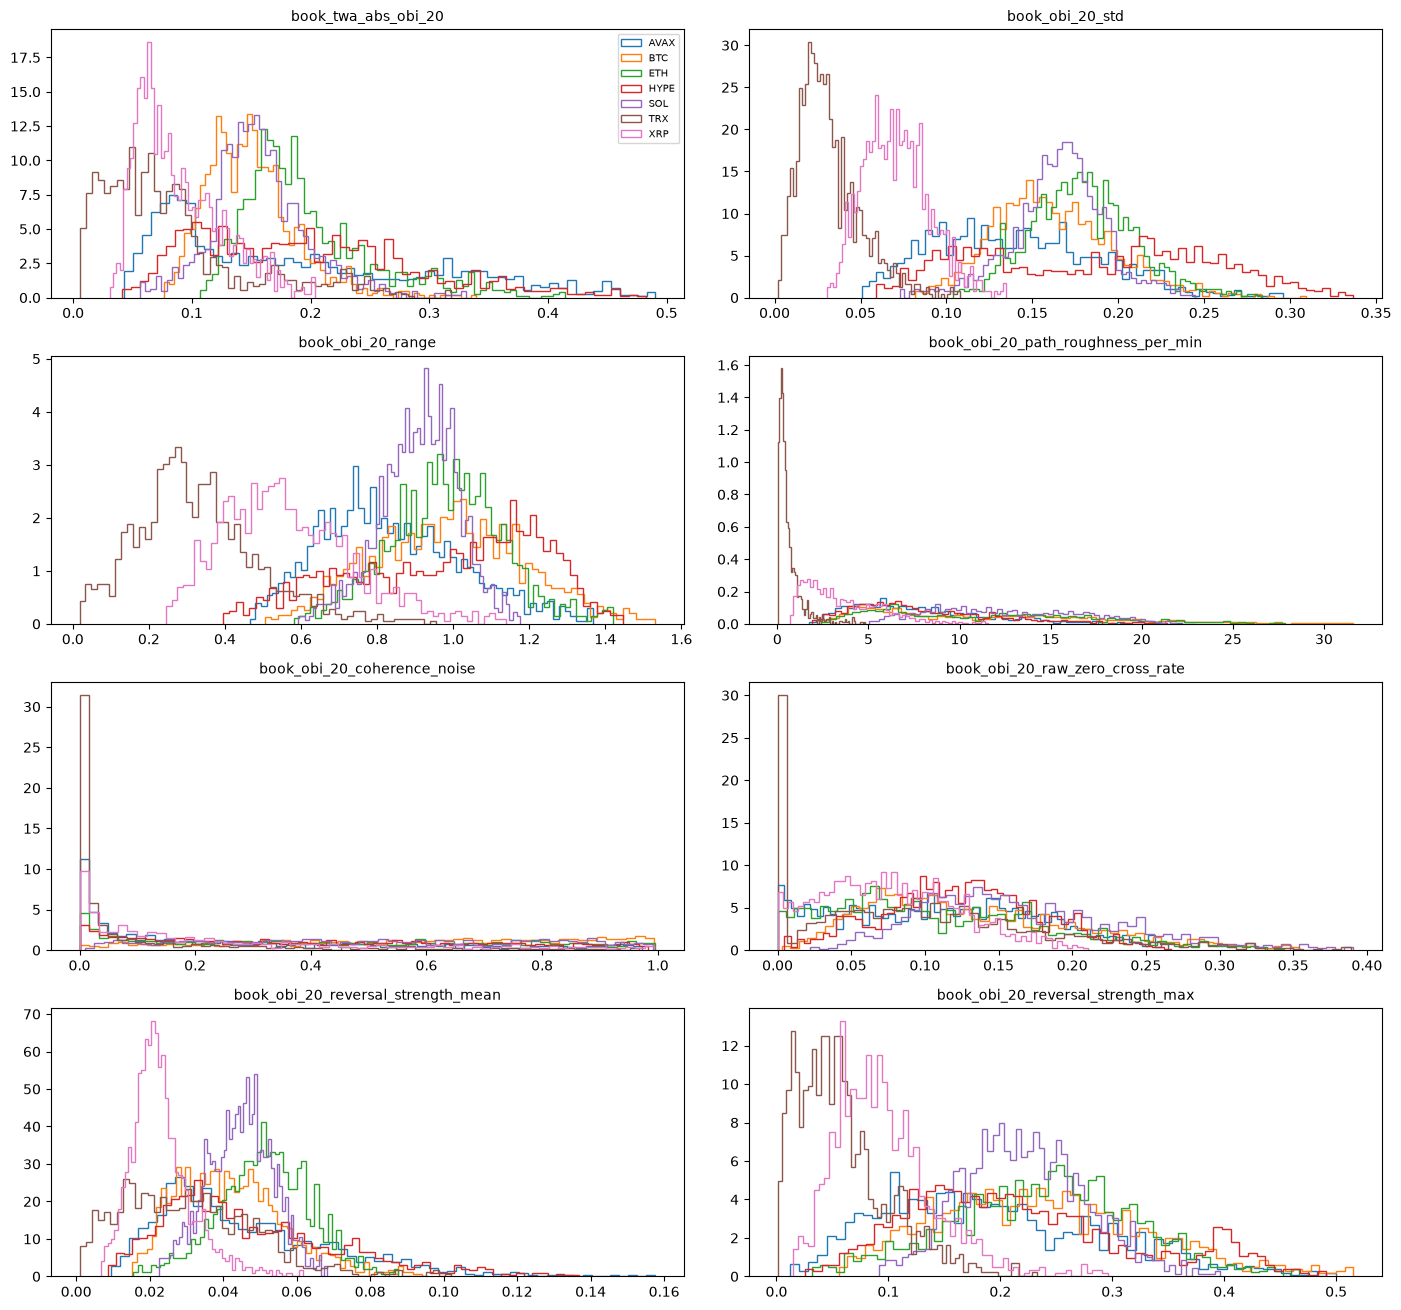

In [6]:
l2_summary = feature_summary(l2, L2_FEATURES, group_col="underlying")
display(l2_summary.round(4))

ncols = 2
fig, axes = plt.subplots(math.ceil(len(L2_FEATURES) / ncols), ncols, figsize=(14, 3.3 * math.ceil(len(L2_FEATURES) / ncols)))
for ax, col in zip(np.atleast_1d(axes).ravel(), L2_FEATURES):
    for asset in ASSETS:
        s = clean_numeric(l2[l2["underlying"] == asset], col)
        if len(s):
            lo, hi = s.quantile(0.005), s.quantile(0.995)
            ax.hist(s[(s >= lo) & (s <= hi)], bins=60, histtype="step", density=True, label=asset)
    ax.set_title(col, fontsize=10)
np.atleast_1d(axes).ravel()[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 6. Time-weighted $|\mathrm{OBI}|$ distribution from the histograms

Aggregating the per-state duration histograms gives the share of book time spent at each imbalance magnitude. This is the empirical basis for any dead-band: $P(|\mathrm{OBI}| < x)$ is the share of time the book would be called "balanced" with $\varepsilon = x$.

Share of book time with |OBI_20| below x:


,P(|OBI|<0.01),P(|OBI|<0.02),P(|OBI|<0.05),P(|OBI|<0.1),P(|OBI|<0.15),P(|OBI|<0.2),P(|OBI|<0.3),P(|OBI|<0.5)
underlying,,,,,,,,
AVAX,5.6,11.4,27.1,46.2,54.7,58.8,69.3,94.8
BTC,4.4,8.7,21.5,41.3,58.1,71.6,88.7,98.9
ETH,3.0,6.1,15.0,29.7,43.4,56.0,76.6,97.3
HYPE,6.4,12.1,24.1,36.7,49.6,61.5,75.0,92.9
SOL,4.4,8.8,21.4,40.0,55.4,68.1,86.0,99.0
TRX,10.8,18.7,38.5,70.8,83.1,90.7,98.9,100.0
XRP,6.8,13.7,35.6,63.1,81.2,92.5,99.2,100.0


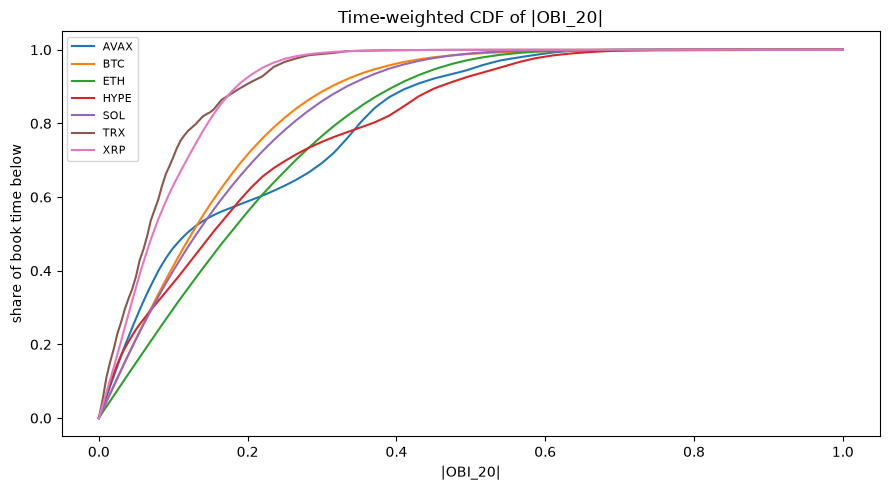

In [7]:
X_GRID = [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50]


def cdf_at(hist_rows, x):
    """Share of mass below x, linear within the quadratic bin that contains x."""
    total = hist_rows.sum()
    if total <= 0:
        return np.nan
    cum = np.concatenate([[0.0], np.cumsum(hist_rows)])
    j = min(int(np.sqrt(x) * N_BINS), N_BINS - 1)
    frac = (x - EDGES[j]) / (EDGES[j + 1] - EDGES[j])
    return (cum[j] + frac * hist_rows[j]) / total


time_cdf = []
for asset in ASSETS:
    m = (dist["underlying"] == asset).to_numpy()
    h = H_abs[m].sum(axis=0)
    time_cdf.append({"underlying": asset, **{f"P(|OBI|<{x})": cdf_at(h, x) for x in X_GRID}})
time_cdf = pd.DataFrame(time_cdf).set_index("underlying")
print("Share of book time with |OBI_20| below x:")
display((100 * time_cdf).round(1))

fig, ax = plt.subplots(figsize=(9, 5))
xs = np.linspace(0, 1, 201)
for asset in ASSETS:
    m = (dist["underlying"] == asset).to_numpy()
    h = H_abs[m].sum(axis=0)
    ax.plot(xs, [cdf_at(h, x) for x in xs], label=asset)
ax.set_xlabel("|OBI_20|")
ax.set_ylabel("share of book time below")
ax.set_title("Time-weighted CDF of |OBI_20|")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Reversal strength and the dead-band trade-off

A raw zero crossing counts every sign change, including flickers between $+0.001$ and $-0.001$. A dead-band $\varepsilon$ would count only reversals whose strength exceeds $\varepsilon$. From the reversal histogram:

$$
\text{reversals}(\varepsilon) = \sum_j H^{rev}_j\, \mathbb{1}\{e_j \ge \varepsilon\} \quad\text{(bin-resolution approximation)}
$$

The table shows how many reversals survive each $\varepsilon$. A natural $\varepsilon$ is one where the surviving count stops dropping steeply (flicker removed) — but **it is not chosen here**: it must be chosen on more history, conditional on spread, depth and volatility.

,raw_reversals,reversals_per_state,kept_eps_0.01,kept_eps_0.02,kept_eps_0.05,kept_eps_0.1,kept_eps_0.15,kept_eps_0.2,kept_eps_0.3
underlying,,,,,,,,,
AVAX,94190,68.452,0.726,0.562,0.290,0.104,0.045,0.023,0.004
BTC,162650,118.205,0.750,0.563,0.302,0.117,0.055,0.022,0.003
ETH,135679,98.604,0.807,0.647,0.372,0.143,0.064,0.024,0.002
HYPE,96730,70.298,0.672,0.501,0.275,0.124,0.062,0.021,0.004
SOL,193097,140.332,0.774,0.588,0.296,0.092,0.033,0.009,0.000
TRX,11442,8.315,0.711,0.502,0.147,0.023,0.005,0.001,0.000
XRP,74863,54.406,0.588,0.355,0.087,0.012,0.003,0.001,0.000


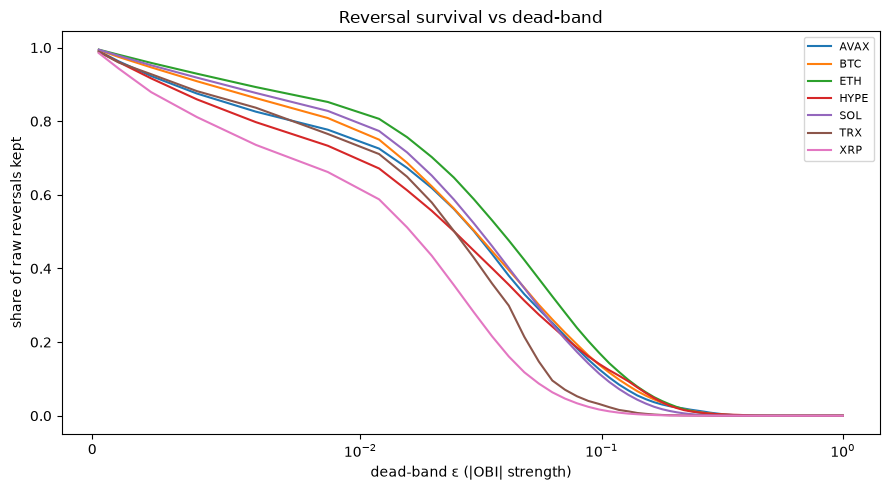

In [8]:
EPS_GRID = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30]
rev_rows = []
for asset in ASSETS:
    m = (dist["underlying"] == asset).to_numpy()
    h = H_rev[m].sum(axis=0)
    total = h.sum()
    row = {"underlying": asset, "raw_reversals": int(total),
           "reversals_per_state": total / max(m.sum(), 1)}
    for e in EPS_GRID[1:]:
        row[f"kept_eps_{e}"] = h[EDGES[:-1] >= e - 1e-12].sum() / total if total else np.nan
    rev_rows.append(row)
reversal_survival = pd.DataFrame(rev_rows).set_index("underlying")
display(reversal_survival.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for asset in ASSETS:
    m = (dist["underlying"] == asset).to_numpy()
    h = H_rev[m].sum(axis=0)
    if h.sum() > 0:
        surv = 1 - np.cumsum(h) / h.sum()
        ax.plot(EDGES[1:], np.concatenate([surv[:-1], [0]]), label=asset)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlabel("dead-band ε (|OBI| strength)")
ax.set_ylabel("share of raw reversals kept")
ax.set_title("Reversal survival vs dead-band")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Part C — What Do the Instability Features Actually Measure?

## 8. Mechanical dependence on activity and volatility

Roughness, zero-cross count and reversal statistics are computed **per book event**. More book updates mechanically produce more path variation and more crossings, even in a perfectly calm book. If the instability features are mostly explained by update count, traded volume, spread or realized volatility, a noise chain built on them would relearn activity or volatility, which the structural model already sees.

The table reports per-asset Spearman correlations and the $R^2$ of an OLS regression of each feature on

$$
\log(1+\text{updates}),\ \log(1+\text{volume}),\ \log \text{spread},\ \log \text{RV}_{1h}.
$$

$1 - R^2$ is the share of variance left for genuine instability. The residual series is kept as a candidate "activity-adjusted" feature.

In [9]:
l2["log_volume"] = pd.to_numeric(l2.get("log1p_volume_usd"), errors="coerce")
l2["log_spread"] = np.log(pd.to_numeric(l2.get("book_twa_spread_bps"), errors="coerce").where(lambda s: s > 0))
l2["log_rv1h"] = np.log(pd.to_numeric(l2.get("realized_vol_1h_annualized"), errors="coerce").where(lambda s: s > 0))
DRIVERS = ["log_updates", "log_volume", "log_spread", "log_rv1h"]

conf_rows, resid_cols = [], {}
for asset, g in l2.groupby("underlying"):
    for col in L2_FEATURES:
        y = pd.to_numeric(g[col], errors="coerce")
        X = g[DRIVERS].apply(pd.to_numeric, errors="coerce")
        ok = y.notna() & X.notna().all(axis=1)
        row = {"underlying": asset, "feature": col, "n": int(ok.sum())}
        for d in DRIVERS:
            row[f"rho_{d}"] = y[ok].corr(X.loc[ok, d], method="spearman") if ok.sum() > 30 else np.nan
        if ok.sum() > 50 and y[ok].nunique() > 10:
            A = np.column_stack([np.ones(ok.sum()), X[ok].to_numpy()])
            beta, *_ = np.linalg.lstsq(A, y[ok].to_numpy(), rcond=None)
            fitted = A @ beta
            ss_res = ((y[ok] - fitted) ** 2).sum()
            ss_tot = ((y[ok] - y[ok].mean()) ** 2).sum()
            row["r2_activity_vol"] = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
            resid_cols.setdefault(f"{col}__resid", pd.Series(np.nan, index=l2.index)).loc[y[ok].index] = y[ok] - fitted
        conf_rows.append(row)
confounding = pd.DataFrame(conf_rows)
for k, v in resid_cols.items():
    l2[k] = v
display(confounding.pivot(index="feature", columns="underlying", values="r2_activity_vol").round(3))
display(confounding.groupby("feature")[[f"rho_{d}" for d in DRIVERS]].median().round(3))

underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,0.039,0.082,0.108,0.042,0.013,0.027,0.058
book_obi_20_path_roughness_per_min,0.578,0.830,0.775,0.489,0.710,0.543,0.803
book_obi_20_range,0.274,0.525,0.364,0.147,0.097,0.480,0.496
book_obi_20_raw_zero_cross_rate,0.072,0.721,0.613,0.117,0.538,0.005,0.343
book_obi_20_reversal_strength_max,0.190,0.463,0.324,0.066,0.077,0.213,0.260
book_obi_20_reversal_strength_mean,0.093,0.605,0.178,0.068,0.124,0.017,0.070
book_obi_20_std,0.231,0.324,0.168,0.104,0.187,0.271,0.073
book_twa_abs_obi_20,0.089,0.032,0.095,0.057,0.146,0.030,0.058


,rho_log_updates,rho_log_volume,rho_log_spread,rho_log_rv1h
feature,,,,
book_obi_20_coherence_noise,0.180,0.095,0.060,0.139
book_obi_20_path_roughness_per_min,0.823,0.418,0.462,0.616
book_obi_20_range,0.486,0.387,0.083,0.417
book_obi_20_raw_zero_cross_rate,0.580,0.240,0.279,0.461
book_obi_20_reversal_strength_max,0.426,0.229,0.151,0.374
book_obi_20_reversal_strength_mean,0.274,0.169,0.127,0.245
book_obi_20_std,0.326,0.139,-0.029,0.296
book_twa_abs_obi_20,-0.059,-0.041,-0.061,-0.143


## 9. Clock dependence

Share of each feature's variance explained by the UTC hour ($\eta^2$), raw and after the activity adjustment of Section 8. The framework requires noise features to be clock-adjusted; a large $\eta^2$ means the clock baseline (Step 2) will remove much of the raw signal. Weekend versus weekday medians are shown separately; with a few days of data the weekend contrast rests on one or two weekends.

underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,0.068,0.033,0.036,0.045,0.052,0.096,0.062
book_obi_20_path_roughness_per_min,0.103,0.122,0.115,0.055,0.103,0.120,0.111
book_obi_20_range,0.095,0.043,0.061,0.023,0.036,0.069,0.054
book_obi_20_raw_zero_cross_rate,0.075,0.115,0.117,0.048,0.122,0.081,0.153
book_obi_20_reversal_strength_max,0.050,0.056,0.024,0.027,0.049,0.068,0.051
book_obi_20_reversal_strength_mean,0.088,0.083,0.040,0.017,0.050,0.074,0.038
book_obi_20_std,0.058,0.033,0.071,0.029,0.046,0.046,0.068
book_twa_abs_obi_20,0.097,0.027,0.066,0.022,0.062,0.225,0.057


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,0.088,0.038,0.064,0.057,0.060,0.099,0.071
book_obi_20_path_roughness_per_min,0.088,0.067,0.107,0.071,0.085,0.097,0.079
book_obi_20_range,0.160,0.040,0.088,0.065,0.049,0.043,0.048
book_obi_20_raw_zero_cross_rate,0.115,0.058,0.096,0.056,0.082,0.093,0.106
book_obi_20_reversal_strength_max,0.075,0.034,0.055,0.040,0.042,0.065,0.032
book_obi_20_reversal_strength_mean,0.125,0.043,0.038,0.033,0.062,0.076,0.061
book_obi_20_std,0.145,0.047,0.077,0.078,0.065,0.060,0.073
book_twa_abs_obi_20,0.220,0.037,0.075,0.051,0.074,0.225,0.083


book_twa_abs_obi_20  book_obi_20_std  book_obi_20_range  book_obi_20_path_roughness_per_min  book_obi_20_coherence_noise  book_obi_20_raw_zero_cross_rate  \
underlying weekend                                                                                                                                                              
AVAX       False                 0.1773           0.1494             0.8591                              8.6533                       0.1695                           0.1149   
           True                  0.1293           0.1218             0.7626                              5.5527                       0.1650                           0.1047   
BTC        False                 0.1518           0.1734             1.0728                             14.4567                       0.6449                           0.1643   
           True                  0.1298           0.1380             0.8332                              5.3740                       0.5078                           0.0754   
ETH        False                 0.1736           0.1868             1.0427                             14.5439                       0.5454                           0.1486   
           True                  0.2067           0.1648             0.8834                              5.8966                       0.1547                           0.0475   
HYPE       False                 0.1589           0.1555             0.9219                              8.3408                       0.3849                           0.1311   
           True                  0.2057           0.2127             1.0838                              6.2921                       0.3428                           0.1161   
SOL        False                 0.1466           0.1614             0.9235                             14.6387                       0.4906                           0.1890   
           True                  0.1611           0.1727             0.9101                              9.6330                       0.5279                           0.1268   
TRX        False                 0.0686           0.0335             0.3600                              0.5472                       0.0262                           0.0923   
           True                  0.0602           0.0212             0.2571                              0.2432                       0.0064                           0.0741   
XRP        False                 0.0713           0.0705             0.6206                              4.4850                       0.2053                           0.0986   
           True                  0.0948           0.0688             0.4372                              1.7676                       0.0924                           0.0481   

                    book_obi_20_reversal_strength_mean  book_obi_20_reversal_strength_max  
underlying weekend                                                                         
AVAX       False                                0.0426                             0.1986  
           True                                 0.0364                             0.1604  
BTC        False                                0.0478                             0.2684  
           True                                 0.0299                             0.1662  
ETH        False                                0.0556                             0.2747  
           True                                 0.0444                             0.1840  
HYPE       False                                0.0402                             0.1930  
           True                                 0.0435                             0.2124  
SOL        False                                0.0454                             0.2242  
           True                                 0.0447                             0.2142  
TRX        False                                0.0292                             

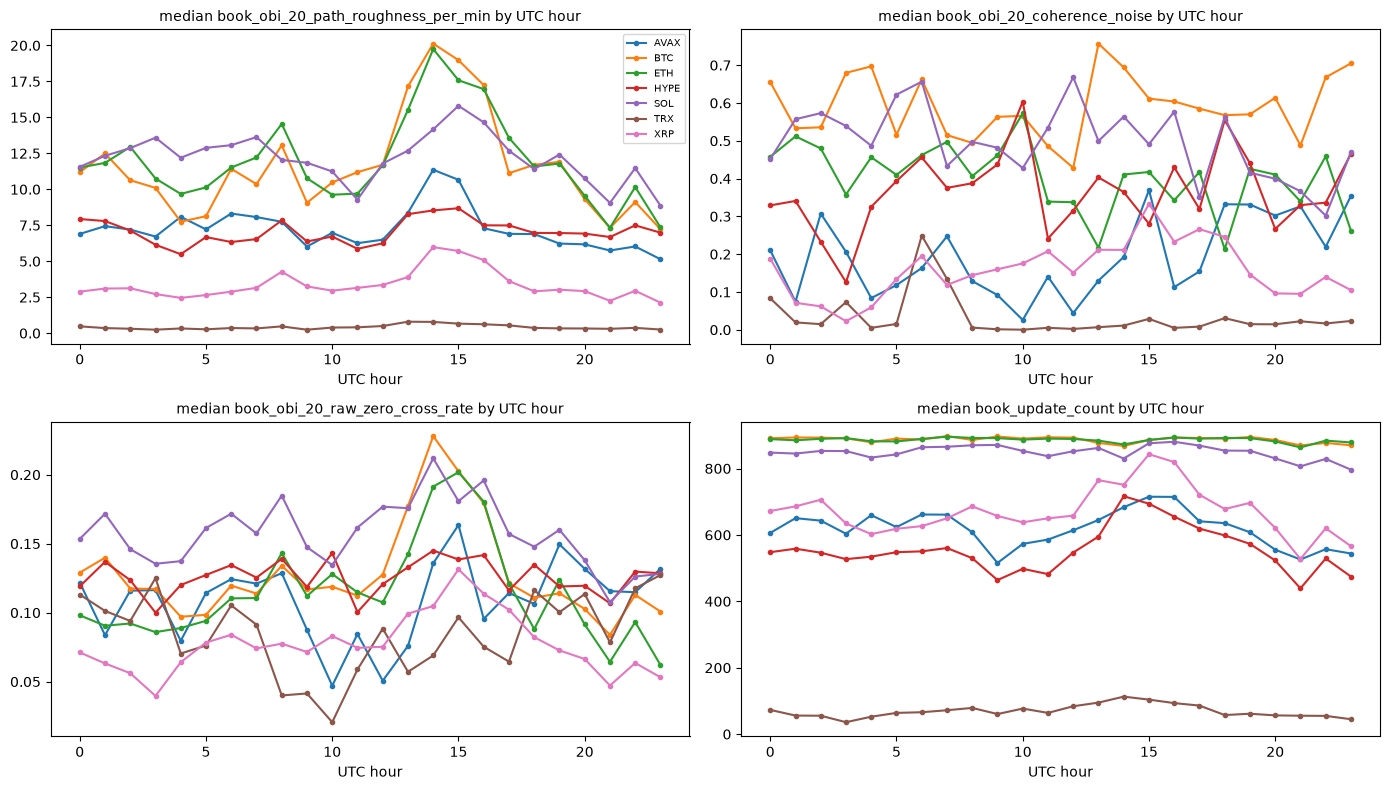

In [10]:
clock_rows = []
for asset, g in l2.groupby("underlying"):
    for col in L2_FEATURES:
        r = f"{col}__resid"
        clock_rows.append({"underlying": asset, "feature": col,
                           "eta2_hour_raw": eta_squared(g, col, "utc_hour"),
                           "eta2_hour_adjusted": eta_squared(g, r, "utc_hour") if r in g else np.nan})
clock = pd.DataFrame(clock_rows)
display(clock.pivot(index="feature", columns="underlying", values="eta2_hour_raw").round(3))
display(clock.pivot(index="feature", columns="underlying", values="eta2_hour_adjusted").round(3))

display(l2.groupby(["underlying", "weekend"])[L2_FEATURES].median().round(4))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), [c for c in ["book_obi_20_path_roughness_per_min", "book_obi_20_coherence_noise",
                                              "book_obi_20_raw_zero_cross_rate", "book_update_count"] if c in l2]):
    m = l2.groupby(["utc_hour", "underlying"])[col].median().unstack()
    for asset in m.columns:
        ax.plot(m.index, m[asset], marker="o", ms=3, label=asset)
    ax.set_title(f"median {col} by UTC hour", fontsize=10)
    ax.set_xlabel("UTC hour")
axes.ravel()[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part D — Structure of the Noise Block

## 10. Redundancy and an observed noise index

Framework §11 requires the latent noise chain to beat an **observed noise index** $N_t$: the first principal component of the deseasonalized instability features. This section builds the in-sample version of that index to see how many independent dimensions the block has.

The PCA is fitted per asset on rank-transformed, activity-adjusted features (robust to the heavy tails and point masses of Section 5). It is **exploratory and in-sample**; a production index must be fitted on training history only.

,n,var_share_pc1,var_share_pc2,load_book_twa_abs_obi_20,load_std,load_range,load_path_roughness_per_min,load_coherence_noise,load_raw_zero_cross_rate,load_reversal_strength_mean,load_reversal_strength_max
underlying,,,,,,,,,,,
AVAX,1122,0.396,0.317,0.207,0.437,0.468,0.388,0.117,0.114,0.401,0.457
BTC,1134,0.386,0.259,0.389,0.452,0.423,0.345,-0.005,-0.027,0.459,0.366
ETH,1131,0.413,0.232,-0.216,0.367,0.380,0.343,0.404,0.384,0.294,0.399
HYPE,1139,0.538,0.239,0.399,0.445,0.422,0.422,-0.015,-0.122,0.369,0.368
SOL,1140,0.397,0.293,0.210,0.448,0.410,0.428,0.172,0.121,0.456,0.391
TRX,906,0.352,0.256,0.177,0.398,0.457,0.454,0.083,0.229,0.344,0.466
XRP,1116,0.347,0.280,0.479,0.405,0.335,0.363,-0.157,-0.249,0.443,0.283


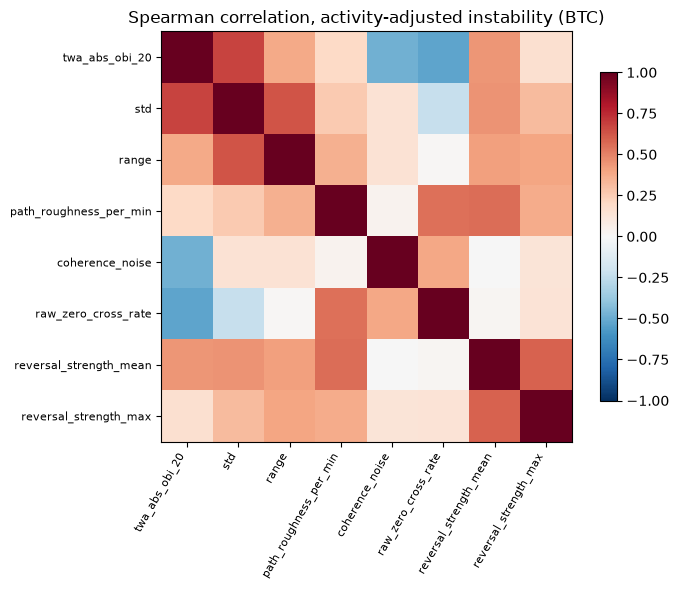

In [11]:
RESID = [f"{c}__resid" for c in L2_FEATURES if f"{c}__resid" in l2.columns]
corr_rows, pca_rows = [], []
l2["noise_index_pc1"] = np.nan
for asset, g in l2.groupby("underlying"):
    Z = g[RESID].rank(pct=True).dropna()
    if len(Z) < 100:
        continue
    C = Z.corr(method="spearman")
    corr_rows.append(C.assign(underlying=asset))
    Zs = (Z - Z.mean()) / Z.std()
    vals, vecs = np.linalg.eigh(np.cov(Zs.T))
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    pc1 = vecs[:, 0] * np.sign(vecs[:, 0].sum())
    l2.loc[Z.index, "noise_index_pc1"] = Zs.to_numpy() @ pc1
    pca_rows.append({"underlying": asset, "n": len(Z),
                     "var_share_pc1": vals[0] / vals.sum(), "var_share_pc2": vals[1] / vals.sum(),
                     **{f"load_{c.replace('book_obi_20_', '').replace('__resid', '')}": w for c, w in zip(RESID, pc1)}})
noise_pca = pd.DataFrame(pca_rows).set_index("underlying")
display(noise_pca.round(3))

if corr_rows:
    btc = [c for c in corr_rows if c["underlying"].iloc[0] == ("BTC" if "BTC" in ASSETS else ASSETS[0])][0].drop(columns="underlying")
    fig, ax = plt.subplots(figsize=(7.5, 6))
    im = ax.imshow(btc.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
    labels = [c.replace("book_obi_20_", "").replace("book_", "").replace("__resid", "") for c in btc.columns]
    ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.set_title("Spearman correlation, activity-adjusted instability (BTC)")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout()
    plt.show()

## 11. Persistence

A noise state is useful only if it persists for more than one bar (otherwise it is i.i.d. dispersion, better handled by a heavy-tailed emission) and decays faster than the structural regime. The ACF is computed on the exact 5-minute grid for the raw features, the activity-adjusted features and the noise index.

lag_minutes                                             5      15     30     60     120
feature                                   underlying                                   
book_obi_20_coherence_noise               AVAX        0.631  0.505  0.425  0.300  0.165
                                          BTC         0.327  0.137  0.093  0.073 -0.000
                                          ETH         0.529  0.354  0.320  0.290  0.256
                                          HYPE        0.373  0.216  0.196  0.214  0.092
                                          SOL         0.445  0.241  0.205  0.128  0.152
                                          TRX         0.475  0.334  0.243  0.171  0.008
                                          XRP         0.558  0.470  0.472  0.408  0.360
book_obi_20_coherence_noise__resid        AVAX        0.608  0.463  0.367  0.245  0.102
                                          BTC         0.244  0.047  0.014  0.024 -0.046
                                          ETH         0.467  0.256  0.216  0.158  0.150
                                          HYPE        0.365  0.193  0.178  0.218  0.095
                                          SOL         0.458  0.253  0.212  0.131  0.131
                                          TRX         0.478  0.336  0.235  0.165  0.010
                                          XRP         0.491  0.417  0.433  0.344  0.281
book_obi_20_path_roughness_per_min        AVAX        0.747  0.653  0.593  0.535  0.475
                                          BTC         0.914  0.848  0.811  0.750  0.669
                                          ETH         0.901  0.856  0.818  0.754  0.662
                                          HYPE        0.810  0.728  0.670  0.632  0.600
                                          SOL         0.809  0.719  0.662  0.569  0.506
                                          TRX         0.674  0.506  0.440  0.363  0.292
                                          XRP         0.839  0.751  0.700  0.602  0.543
book_obi_20_path_roughness_per_min__resid AVAX        0.568  0.407  0.285  0.246  0.252
                                          BTC         0.641  0.416  0.333  0.197  0.122
                                          ETH         0.600  0.456  0.366  0.169  0.112
                                          HYPE        0.717  0.658  0.585  0.536  0.521
                                          SOL         0.602  0.453  0.380  0.274  0.201
                                          TRX         0.415  0.280  0.194  0.030  0.027
                                          XRP         0.525  0.324  0.250  0.124  0.111
book_obi_20_range                         AVAX        0.576  0.504  0.462  0.397  0.397
                                          BTC         0.656  0.595  0.558  0.499  0.491
                                          ETH         0.568  0.526  0.503  0.504  0.464
                                          HYPE        0.762  0.719  0.689  0.657  0.661
                                          SOL         0.404  0.358  0.330  0.307  0.269
                                          TRX         0.461  0.369  0.304  0.313  0.261
                                          XRP         0.530  0.430  0.454  0.402  0.369
book_obi_20_range__resid                  AVAX        0.449  0.363  0.284  0.267  0.191
                                          BTC         0.306  0.215  0.178  0.105  0.140
                                          ETH         0.366  0.324  0.277  0.279  0.241
                                          HYPE        0.711  0.663  0.608  0.537  0.525
                                          SOL         0.323  0.273  0.238  0.223  0.160
                                          TRX         0.174  0.127  0.049 -0.003  0.087
                                          XRP         0.166  0.067  0.143  0.091  0.034
book_obi_20_raw_zero_cross_rate           AVAX        0.675  0.560  0.465  0.349  0.264
                                        

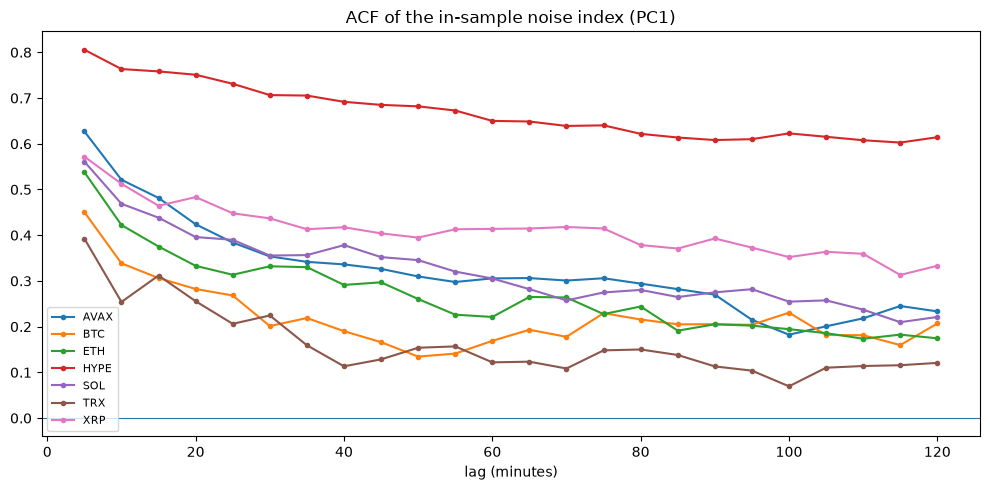

In [12]:
acf_frames = [grid_acf(l2, c, 24) for c in L2_FEATURES + ["noise_index_pc1"] if c in l2.columns]
acf_frames += [grid_acf(l2, c, 24) for c in RESID]
l2_acf = pd.concat(acf_frames, ignore_index=True)
display(
    l2_acf[l2_acf["lag_minutes"].isin([5, 15, 30, 60, 120])]
    .pivot_table(index=["feature", "underlying"], columns="lag_minutes", values="acf")
    .round(3)
)

fig, ax = plt.subplots(figsize=(10, 5))
for asset, g in l2_acf[l2_acf["feature"] == "noise_index_pc1"].groupby("underlying"):
    ax.plot(g["lag_minutes"], g["acf"], marker="o", ms=3, label=asset)
ax.axhline(0, linewidth=0.8)
ax.set_title("ACF of the in-sample noise index (PC1)")
ax.set_xlabel("lag (minutes)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 12. Book noise versus price-path noise (collector v0.3 rows)

Collector v0.3 samples the book mid every 10 seconds inside each bar. Two price-path statistics measure how noisily price itself moved:

$$
\text{RV}^{path}_t = \sum_i \left(\ln m_{i} - \ln m_{i-1}\right)^2, \qquad \text{flip share}_t = \frac{\#\{\text{sign}(\Delta \ln m_i) \ne \text{sign}(\Delta \ln m_{i-1})\}}{\#\{\text{non-zero increments}\}}
$$

If book instability is a measure of noisy price action, it should correlate with the flip share and with the ratio of intrawindow RV to the squared bar return (a high ratio means a lot of movement that went nowhere). With about two days of v0.3 rows this is a first look only.

In [13]:
if {"mid_path_realized_variance", "mid_path_return_sign_flips", "mid_path_nonzero_increments"}.issubset(l2.columns):
    v3 = l2[pd.to_numeric(l2["mid_path_realized_variance"], errors="coerce").notna()].copy()
    v3["flip_share"] = pd.to_numeric(v3["mid_path_return_sign_flips"], errors="coerce") / pd.to_numeric(
        v3["mid_path_nonzero_increments"], errors="coerce").where(lambda s: s > 1)
    r2 = pd.to_numeric(v3["return_5m"], errors="coerce") ** 2
    v3["path_inefficiency"] = np.log(pd.to_numeric(v3["mid_path_realized_variance"], errors="coerce") / r2.where(r2 > 0))
    print(f"v0.3 L2-ready states: {len(v3):,}")
    rows = []
    for asset, g in v3.groupby("underlying"):
        for col in L2_FEATURES + ["noise_index_pc1"]:
            if col not in g:
                continue
            rows.append({"underlying": asset, "feature": col, "n": int(g[col].notna().sum()),
                         "rho_flip_share": g[col].corr(g["flip_share"], method="spearman"),
                         "rho_path_inefficiency": g[col].corr(g["path_inefficiency"], method="spearman"),
                         "rho_path_rv": g[col].corr(pd.to_numeric(g["mid_path_realized_variance"], errors="coerce"), method="spearman")})
    path_link = pd.DataFrame(rows)
    display(path_link.pivot(index="feature", columns="underlying", values="rho_flip_share").round(3))
    display(path_link.pivot(index="feature", columns="underlying", values="rho_path_inefficiency").round(3))
else:
    path_link = pd.DataFrame()
    print("No collector v0.3 mid-path fields in canonical_market_state; section skipped.")

v0.3 L2-ready states: 3,248


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,0.028,0.061,-0.053,-0.007,-0.006,-0.012,-0.064
book_obi_20_path_roughness_per_min,0.023,0.078,-0.082,-0.002,-0.035,0.020,-0.009
book_obi_20_range,-0.041,0.095,-0.048,-0.006,0.029,0.049,-0.070
book_obi_20_raw_zero_cross_rate,0.066,0.052,-0.059,0.016,-0.047,-0.017,0.010
book_obi_20_reversal_strength_max,0.076,0.011,-0.051,-0.034,-0.045,0.021,-0.015
book_obi_20_reversal_strength_mean,0.025,0.087,-0.028,0.025,0.030,0.044,0.010
book_obi_20_std,-0.062,0.071,-0.003,-0.031,-0.020,-0.017,-0.118
book_twa_abs_obi_20,-0.035,0.031,0.039,-0.010,0.015,-0.034,-0.026
noise_index_pc1,-0.003,-0.003,-0.053,0.009,-0.033,0.037,-0.022


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,-0.019,-0.028,0.028,-0.063,0.072,0.135,-0.014
book_obi_20_path_roughness_per_min,-0.020,0.022,-0.034,0.060,0.015,0.151,-0.032
book_obi_20_range,-0.060,0.064,-0.022,0.032,0.053,0.107,-0.036
book_obi_20_raw_zero_cross_rate,0.001,0.003,-0.000,-0.021,0.009,0.067,-0.072
book_obi_20_reversal_strength_max,-0.062,-0.001,0.031,0.007,0.049,0.043,-0.039
book_obi_20_reversal_strength_mean,-0.042,0.076,-0.044,-0.004,0.113,-0.021,0.024
book_obi_20_std,-0.048,0.038,-0.041,0.057,0.019,0.030,0.017
book_twa_abs_obi_20,-0.045,0.057,-0.035,0.081,-0.025,-0.060,0.057
noise_index_pc1,-0.072,0.025,0.056,0.028,0.060,-0.083,0.060


# Part E — Relation to the Structural Model

## 13. Dispersion, not direction

Framework §11 allows the noise state to scale dispersion only. On the next index return $r_{t+1}$:

- **dispersion test:** Spearman correlation of the noise index at $t$ with $|r_{t+1}|$, and the same after removing what trailing RV already explains (partial correlation on ranks);
- **direction test:** correlation of the noise index with $r_{t+1}$ and with $r_{t+1} \cdot \text{sign}(\mathrm{OBI}_t)$ — any noticeable value would mean the "noise" carries directional information and cannot be a pure dispersion state.

The OBI level itself is shown for comparison: a directional link between $\mathrm{OBI}_t$ and $r_{t+1}$ belongs in the exhaustion/transition block, not the noise block.

In [14]:
l2["next_return"] = lead(l2, "return_5m", 1)
l2["next_abs_return"] = l2["next_return"].abs()
l2["obi_sign_next_return"] = l2["next_return"] * np.sign(pd.to_numeric(l2["book_twa_obi_20"], errors="coerce"))


def partial_spearman(x, y, z):
    d = pd.concat([x, y, z], axis=1).dropna().rank()
    if len(d) < 50:
        return np.nan
    def resid(a, b):
        A = np.column_stack([np.ones(len(b)), b])
        return a - A @ np.linalg.lstsq(A, a, rcond=None)[0]
    return np.corrcoef(resid(d.iloc[:, 0].to_numpy(), d.iloc[:, 2].to_numpy()),
                       resid(d.iloc[:, 1].to_numpy(), d.iloc[:, 2].to_numpy()))[0, 1]


rows = []
for asset, g in l2.groupby("underlying"):
    for col in ["noise_index_pc1"] + L2_FEATURES + ["book_twa_obi_20"]:
        if col not in g:
            continue
        x = pd.to_numeric(g[col], errors="coerce")
        rows.append({
            "underlying": asset, "feature": col,
            "rho_next_abs_return": x.corr(g["next_abs_return"], method="spearman"),
            "partial_rho_given_rv": partial_spearman(x, g["next_abs_return"], g["log_rv1h"]),
            "rho_next_return": x.corr(g["next_return"], method="spearman"),
            "rho_next_return_x_obi_sign": x.corr(g["obi_sign_next_return"], method="spearman"),
            "n": int((x.notna() & g["next_return"].notna()).sum()),
        })
return_link = pd.DataFrame(rows)
display(return_link.pivot(index="feature", columns="underlying", values="partial_rho_given_rv").round(3))
display(return_link.pivot(index="feature", columns="underlying", values="rho_next_return").round(3))
n_min = int(return_link["n"].min()) if len(return_link) else 0
print(f"Approximate 95% band for a zero correlation at n={n_min:,}: ±{1.96 / math.sqrt(max(n_min, 1)):.3f} "
      "(ignores serial dependence, so it is too narrow)")

underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,0.025,-0.027,0.018,0.074,-0.008,-0.008,-0.010
book_obi_20_path_roughness_per_min,0.102,0.181,0.164,0.048,0.117,0.116,0.085
book_obi_20_range,0.071,0.113,0.034,-0.016,-0.031,0.077,0.063
book_obi_20_raw_zero_cross_rate,0.025,0.111,0.141,0.035,0.115,-0.011,0.036
book_obi_20_reversal_strength_max,0.075,0.064,0.051,-0.004,0.010,0.063,0.026
book_obi_20_reversal_strength_mean,0.061,0.112,0.059,0.006,-0.022,0.053,0.022
book_obi_20_std,0.080,0.109,-0.016,-0.032,-0.088,0.078,-0.027
book_twa_abs_obi_20,0.028,0.079,-0.038,-0.053,-0.100,0.073,-0.029
book_twa_obi_20,0.031,0.029,0.054,0.049,0.033,0.036,0.004


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
book_obi_20_coherence_noise,-0.030,-0.021,-0.009,0.017,-0.022,0.029,-0.037
book_obi_20_path_roughness_per_min,-0.049,-0.036,-0.024,-0.013,-0.057,-0.004,-0.037
book_obi_20_range,-0.011,-0.048,-0.039,0.004,-0.015,-0.004,-0.019
book_obi_20_raw_zero_cross_rate,-0.060,-0.027,-0.013,0.018,-0.061,0.026,-0.026
book_obi_20_reversal_strength_max,-0.026,-0.002,-0.028,0.010,-0.004,0.057,-0.007
book_obi_20_reversal_strength_mean,-0.008,-0.028,-0.053,0.015,-0.007,0.044,-0.004
book_obi_20_std,-0.024,-0.035,-0.055,0.006,0.023,0.009,-0.016
book_twa_abs_obi_20,0.004,-0.035,-0.037,-0.018,0.022,-0.017,0.022
book_twa_obi_20,-0.050,0.011,0.014,-0.016,0.020,-0.031,0.011


Approximate 95% band for a zero correlation at n=894: ±0.066 (ignores serial dependence, so it is too narrow)


## 14. Cross-asset synchronicity

If book instability is mostly a market-wide phenomenon (all books get noisy together), one pooled noise state may suffice; if it is asset-specific, each asset needs its own. Pairwise Spearman correlation of the noise index across assets at the same timestamp:

In [15]:
wide = l2.pivot_table(index="state_time", columns="underlying", values="noise_index_pc1")
noise_sync = wide.corr(method="spearman")
display(noise_sync.round(2))

underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
underlying,,,,,,,
AVAX,1.00,0.01,0.00,-0.15,-0.06,0.17,-0.02
BTC,0.01,1.00,0.09,0.17,0.05,0.00,0.03
ETH,0.00,0.09,1.00,-0.19,-0.10,0.01,-0.07
HYPE,-0.15,0.17,-0.19,1.00,0.21,-0.15,0.13
SOL,-0.06,0.05,-0.10,0.21,1.00,0.02,-0.01
TRX,0.17,0.00,0.01,-0.15,0.02,1.00,-0.05
XRP,-0.02,0.03,-0.07,0.13,-0.01,-0.05,1.00


# Part F — Research Handoff

## 15. Interpretation checklist

1. **Integrity:** are out-of-order updates and non-monotonic states zero, and do both histogram identities hold exactly?
2. **Coverage:** do any assets have bars with very few book updates (TRX, XRP), making the event-sampled statistics unreliable?
3. **Activity confounding:** what share of each feature's variance is explained by updates, volume, spread and RV? Which features keep a meaningful residual?
4. **Clock:** how much hour-of-day structure remains after the activity adjustment?
5. **Dimensions:** how much variance does PC1 explain? Is one noise index enough, or are there two distinct dimensions (for example level-type vs. flicker-type)?
6. **Persistence:** does the noise index persist for several bars and decay within about an hour?
7. **Price-path link (v0.3):** does book noise correlate with noisy price paths (flip share, path inefficiency)?
8. **Dispersion vs direction:** does the noise index predict $|r_{t+1}|$ beyond trailing RV, and is it free of directional information?
9. **Synchronicity:** is book noise market-wide or asset-specific?
10. **$\varepsilon$:** where does the reversal-survival curve flatten per asset? Record it as a hypothesis only; calibrate after at least 30 days.
11. **History:** which of these conclusions would change with 30–60 days of data?

**Do not fit the noise chain here.** Per framework v2.1 §21, $Q_t$ is added only once 60 or more days of post-correction L2 data exist, and must beat the observed noise index out of sample.

In [16]:
l2_report = {
    "audit": aud.reset_index(),
    "histogram_invariants": inv,
    "feature_summary": l2_summary,
    "time_cdf_abs_obi": time_cdf.reset_index(),
    "reversal_survival": reversal_survival.reset_index(),
    "activity_confounding": confounding,
    "clock_eta2": clock,
    "noise_pca": noise_pca.reset_index(),
    "acf": l2_acf,
    "path_link": path_link,
    "return_link": return_link,
    "noise_sync": noise_sync.reset_index(),
}
print("L2 report sections:")
for k, v in l2_report.items():
    print(f"  {k:<22} {len(v):>8,} rows")

L2 report sections:
  audit                         7 rows
  histogram_invariants      9,632 rows
  feature_summary              56 rows
  time_cdf_abs_obi              7 rows
  reversal_survival             7 rows
  activity_confounding         56 rows
  clock_eta2                   56 rows
  noise_pca                     7 rows
  acf                       2,856 rows
  path_link                    63 rows
  return_link                  70 rows
  noise_sync                    7 rows


## 16. Close the read-only connection

In [17]:
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
